# Module 2 — Differential Gene Expression

**Goal:** Identify genes whose expression level differs significantly between each PAM50 subtype and all other subtypes combined (one-vs-rest).

**Method:**

- **Input data:** UCSC Xena stores STAR counts as log₂(count + 1) — the file is already normalized, so no further transform is applied.
- **Test:** Welch's t-test (does not assume equal variance — appropriate because group sizes differ).
- **Multiple testing:** 5 subtypes × 6 000 genes = 30 000 tests. Benjamini-Hochberg FDR correction applied within each subtype's 6 000 tests.
- **Significance threshold:** FDR < 0.05 **and** |log₂FC| ≥ 1.0 (at least 2× fold change).

A gene with log₂FC > 0 is **upregulated** in the subtype; log₂FC < 0 means **downregulated**.


In [1]:
import sys
sys.path.insert(0, "..")

import logging
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.constants import InterimFile, KNOWN_MARKERS
from src.paths import interim_file
from src.features.differential_expression import run_one_vs_rest, run_pairwise, top_de_genes
from src.visualization.volcano import plot_all_volcanos
from src.data.annotation import fetch_gene_symbols, annotate_de_results

logging.basicConfig(level=logging.INFO, format="%(message)s")

## Load Data


In [2]:
X = pd.read_csv(interim_file(InterimFile.X), index_col=0)
labels = pd.read_csv(interim_file(InterimFile.LABELS), index_col=0).squeeze()

print(f"X:      {X.shape[0]:>5} samples x {X.shape[1]:>5} genes")
print(f"labels: {len(labels):>5} samples")
print()
print(labels.value_counts())

X:        842 samples x  6000 genes
labels:   842 samples

PAM50Call_RNAseq
LumA      421
LumB      192
Basal     139
Her2       67
Normal     23
Name: count, dtype: int64


## Run Differential Expression


In [3]:
FDR_THRESHOLD = 0.05
LOG2FC_THRESHOLD = 1.0  # >= 2x fold change

results = run_one_vs_rest(
    X=X,
    labels=labels,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
)
results.head(3)

One-vs-rest DGE: 5 subtypes × 6000 genes = 30000 tests


  Basal     n=139


  Her2      n=67


  LumA      n=421


  LumB      n=192


  Normal    n=23


Significant pairs (FDR<0.05, |log2FC|≥1.0): 8629 / 30000


,gene,subtype,log2fc,pval,padj,mean_subtype,mean_rest,n_subtype,n_rest,significant
0,ENSG00000166509.12,Basal,-4.947040,6.778063e-47,9.037418e-46,2.192265,7.139305,139,703,True
1,ENSG00000110484.7,Basal,-6.277185,8.148238e-40,7.872693e-39,5.805762,12.082947,139,703,True
2,ENSG00000153002.12,Basal,-5.271251,8.501611e-47,1.126041e-45,4.102785,9.374036,139,703,True


## Gene Symbol Annotation

Map Ensembl IDs to HGNC symbols via MyGene.info (cached locally after first run).


In [4]:
base_ids = list(dict.fromkeys(results["gene"].str.split(".").str[0]))
annotation = fetch_gene_symbols(ensembl_ids=base_ids, cache_path=interim_file(InterimFile.GENE_ANNOTATION))

results = annotate_de_results(results, annotation)
print(f"Symbols mapped: {results['symbol'].notna().sum():,} / {len(results):,}")
results[["gene", "symbol"]].drop_duplicates().head(5)

Loading gene annotation from cache: gene_annotation.csv.gz


Symbols mapped: 22,495 / 30,000


,gene,symbol
0,ENSG00000166509.12,CLEC3A
1,ENSG00000110484.7,SCGB2A2
2,ENSG00000153002.12,CPB1
3,ENSG00000134184.13,GSTM1
4,ENSG00000160182.3,TFF1


## Significant Genes per Subtype

How many gene-subtype pairs pass the threshold, broken down by direction?


In [5]:
sig = results[results["significant"]].copy()
sig["direction"] = sig["log2fc"].apply(lambda x: "up" if x > 0 else "down")

summary = (
    sig.groupby(["subtype", "direction"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=["up", "down"])
)
summary["total"] = summary.sum(axis=1)
summary.sort_values("total", ascending=False)

direction,up,down,total
subtype,,,
Basal,1415,1615,3030
Normal,1300,474,1774
Her2,694,822,1516
LumA,959,494,1453
LumB,282,574,856


## Top DE Genes per Subtype

Top 10 up- and downregulated genes per subtype (ranked by adjusted p-value).


In [6]:
display_cols = ["subtype", "symbol", "gene", "log2fc", "padj", "mean_subtype", "mean_rest"]
fmt = {"log2fc": "{:.2f}", "padj": "{:.2e}", "mean_subtype": "{:.2f}", "mean_rest": "{:.2f}"}

print("=== Top 10 upregulated per subtype ===")
top_up = top_de_genes(results, n=10, direction="up")
display(
    top_up[display_cols]
    .style.format(fmt)
    .background_gradient(subset="log2fc", cmap="Reds")
)

print("=== Top 10 downregulated per subtype ===")
top_down = top_de_genes(results, n=10, direction="down")
display(
    top_down[display_cols]
    .style.format(fmt)
    .background_gradient(subset="log2fc", cmap="Blues_r")
)

=== Top 10 upregulated per subtype ===


,subtype,symbol,gene,log2fc,padj,mean_subtype,mean_rest
0,Basal,BCL11A,ENSG00000119866.22,4.54,9.88e-111,11.05,6.50
1,Basal,FOXCUT,ENSG00000280916.2,6.54,5.77e-83,8.98,2.44
2,Basal,FOXC1,ENSG00000054598.9,4.10,2.31e-79,12.44,8.35
3,Basal,EEF1DP5,ENSG00000213130.3,4.20,1.31e-76,5.72,1.53
4,Basal,CDCA7,ENSG00000144354.14,3.16,8.95e-75,10.76,7.59
5,Basal,PSAT1,ENSG00000135069.14,4.24,4.85e-72,11.54,7.30
6,Basal,LOC101929004,ENSG00000288009.1,3.14,1.27e-71,5.66,2.52
7,Basal,B3GNT5,ENSG00000176597.12,2.85,3.06e-70,10.52,7.66
8,Basal,ROPN1,ENSG00000065371.17,6.54,1.66e-69,8.84,2.30
9,Basal,BLACAT1,ENSG00000281406.2,4.62,3.16e-69,7.97,3.35


=== Top 10 downregulated per subtype ===


,subtype,symbol,gene,log2fc,padj,mean_subtype,mean_rest
0,Basal,RAD17P1,ENSG00000232400.1,-4.78,1.60e-189,0.41,5.19
1,Basal,nan,ENSG00000225208.1,-3.44,1.41e-171,0.18,3.62
2,Basal,RNU6-813P,ENSG00000207422.1,-3.37,8.60e-148,0.12,3.50
3,Basal,nan,ENSG00000253768.1,-5.15,8.04e-138,0.73,5.89
4,Basal,nan,ENSG00000223808.1,-6.05,2.24e-136,0.67,6.72
5,Basal,FSIP1,ENSG00000150667.8,-5.11,5.79e-136,4.31,9.43
6,Basal,SRARP,ENSG00000183888.4,-6.80,4.80e-132,1.03,7.83
7,Basal,DSCAM-AS1,ENSG00000235123.5,-5.97,8.22e-129,0.52,6.49
8,Basal,VN1R53P,ENSG00000236313.1,-5.37,1.24e-127,0.71,6.08
9,Basal,RN7SL314P,ENSG00000244402.3,-4.48,2.71e-126,0.50,4.98


## Volcano Plots

Each point is one gene. x-axis = log₂FC (positive = higher in this subtype). y-axis = -log₁₀(FDR-adjusted p-value). Red = significantly up, blue = significantly down, grey = not significant. Dashed lines mark the thresholds.


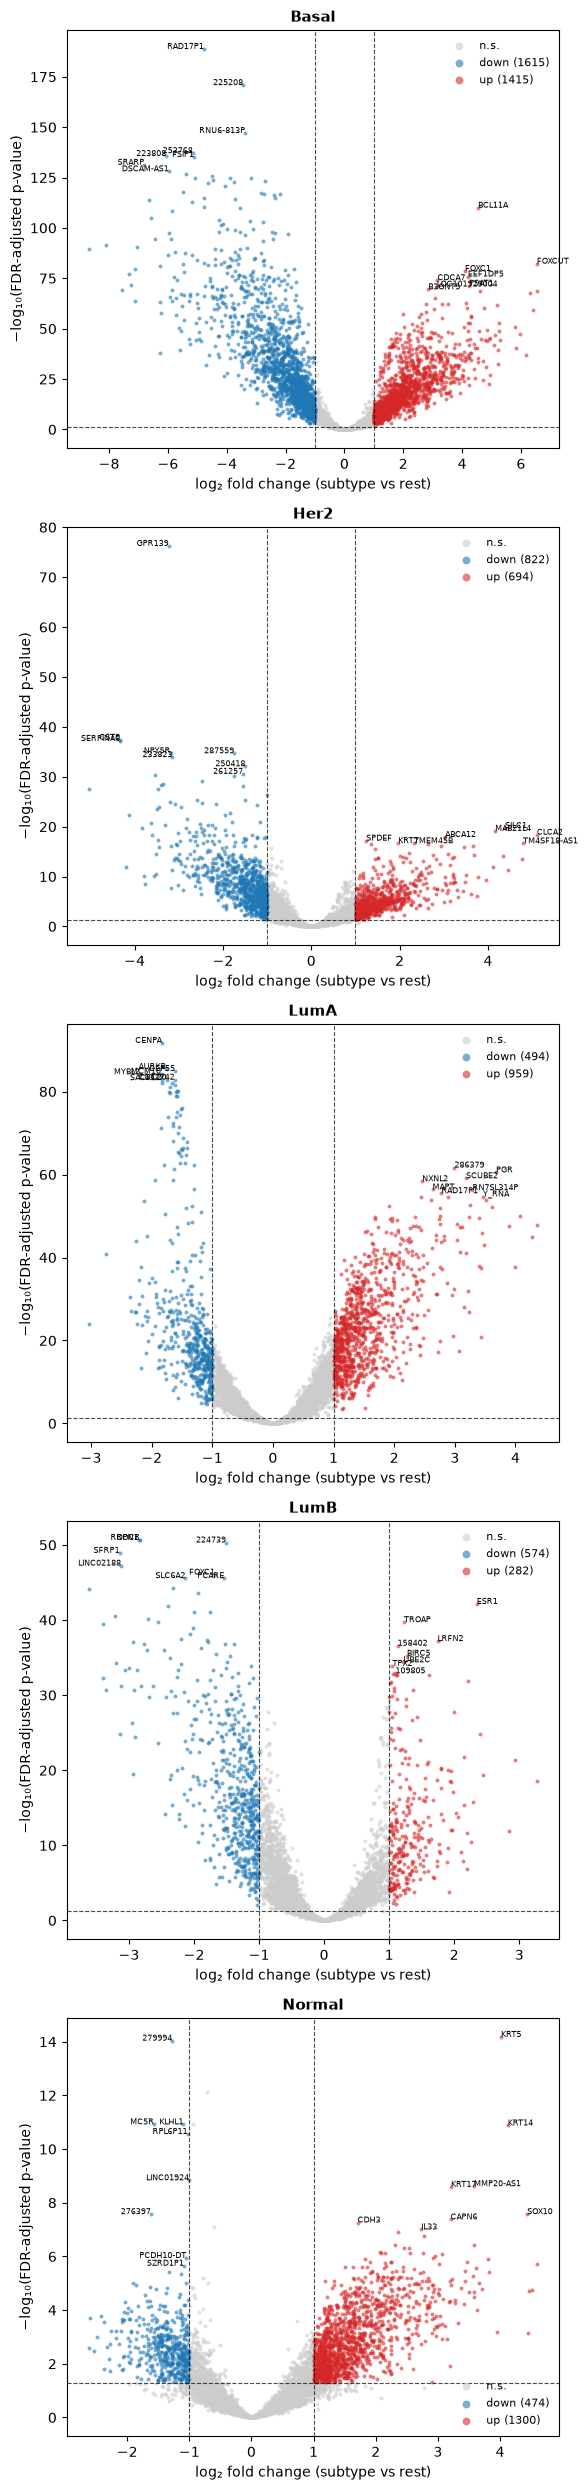

In [7]:
fig = plot_all_volcanos(
    results,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
    n_label=8,
    ncols=1,
)
plt.show()

## Known Marker Validation

A credible DGE result should recover established PAM50 biomarkers. We check whether canonical markers from the literature appear in our significant genes.


In [8]:
results["gene_base"] = results["gene"].str.split(".").str[0]

rows = []
for subtype, marker_ids in KNOWN_MARKERS.items():
    for ensembl_id in marker_ids:
        hit = results[
            (results["subtype"] == subtype) & (results["gene_base"] == ensembl_id)
        ]
        if hit.empty:
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top6000": False, "significant": False,
                         "log2fc": None, "padj": None})
        else:
            r = hit.iloc[0]
            rows.append({"subtype": subtype, "ensembl_id": ensembl_id,
                         "in_top6000": True, "significant": bool(r["significant"]),
                         "log2fc": round(float(r["log2fc"]), 2),
                         "padj": f"{r['padj']:.2e}"})

marker_df = pd.DataFrame(rows)
print(f"Markers in top-6000 variable genes: {marker_df['in_top6000'].sum()} / {len(marker_df)}")
print(f"Markers also significant:           {marker_df['significant'].sum()} / {marker_df['in_top6000'].sum()}")
marker_df

Markers in top-6000 variable genes: 11 / 16
Markers also significant:           9 / 11


,subtype,ensembl_id,in_top6000,significant,log2fc,padj
0,Basal,ENSG00000012048,False,False,NaN,None
1,Basal,ENSG00000186081,True,True,3.04,8.18e-21
2,Basal,ENSG00000143228,True,True,1.51,2.96e-36
3,Basal,ENSG00000166033,False,False,NaN,None
4,Her2,ENSG00000141736,True,True,2.77,3.80e-15
5,Her2,ENSG00000140443,True,True,-2.33,5.81e-21
6,Her2,ENSG00000132965,False,False,NaN,None
7,LumA,ENSG00000091831,True,True,3.12,3.56e-48
8,LumA,ENSG00000129514,True,True,2.22,1.72e-33
9,LumA,ENSG00000107485,True,True,1.86,1.51e-38


## Pairwise Differential Expression

One-vs-rest shows what makes each subtype unique against the pooled rest. Pairwise compares each pair of subtypes directly, giving sharper fold changes and removing the dilution effect of mixing dissimilar groups into "rest".


In [9]:
pairwise = run_pairwise(
    X=X,
    labels=labels,
    fdr_threshold=FDR_THRESHOLD,
    log2fc_threshold=LOG2FC_THRESHOLD,
)
pairwise = annotate_de_results(pairwise, annotation)
print(f"Pairwise: {len(pairwise):,} rows  |  significant: {pairwise['significant'].sum():,}")
pairwise.head(3)

Pairwise DGE: 10 pairs × 6000 genes = 60000 tests


  Basal    vs Her2      n=(139, 67)


  Basal    vs LumA      n=(139, 421)


  Basal    vs LumB      n=(139, 192)


  Basal    vs Normal    n=(139, 23)


...

  LumA     vs Normal    n=(421, 23)


  LumB     vs Normal    n=(192, 23)


Significant pairs (FDR<0.05, |log2FC|≥1.0): 23125 / 60000


Pairwise: 60,000 rows  |  significant: 23,125


,gene,subtype_a,subtype_b,log2fc,pval,padj,mean_a,mean_b,n_a,n_b,significant,symbol
0,ENSG00000166509.12,Basal,Her2,-4.139507,3.769665e-08,1.731852e-07,2.192265,6.331772,139,67,True,CLEC3A
1,ENSG00000110484.7,Basal,Her2,-6.221160,2.034666e-13,1.892713e-12,5.805762,12.026922,139,67,True,SCGB2A2
2,ENSG00000153002.12,Basal,Her2,-0.912087,7.315387e-02,1.136518e-01,4.102785,5.014873,139,67,False,CPB1


### Heatmap: Significant DE Genes per Subtype Pair

Each cell shows how many genes are significantly different between the two subtypes. Darker = more distinct. Diagonal is zero (a subtype vs itself).


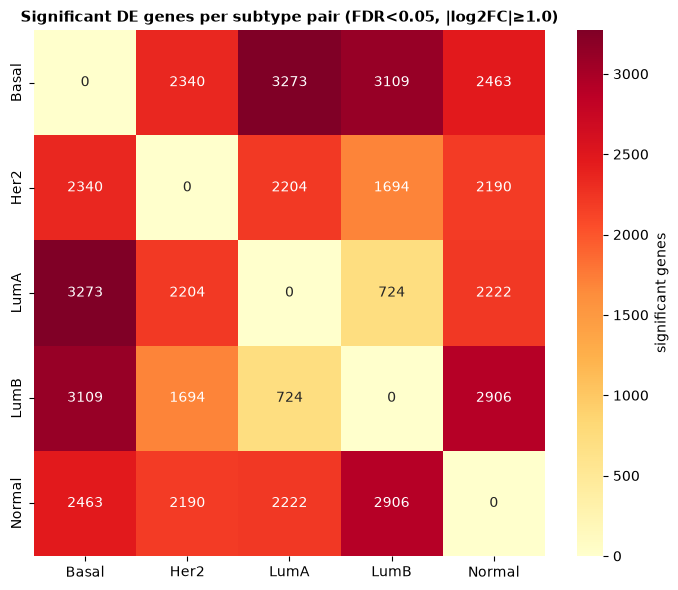

In [10]:
subtypes = sorted(labels.unique())
mat = pd.DataFrame(0, index=subtypes, columns=subtypes)
sig_counts = pairwise[pairwise["significant"]].groupby(["subtype_a", "subtype_b"]).size()
for (a, b), count in sig_counts.items():
    mat.loc[a, b] = count
    mat.loc[b, a] = count  # symmetric

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    mat, annot=True, fmt="d", cmap="YlOrRd", ax=ax,
    cbar_kws={"label": "significant genes"},
)
ax.set_title(
    f"Significant DE genes per subtype pair (FDR<{FDR_THRESHOLD}, |log2FC|≥{LOG2FC_THRESHOLD})",
    fontsize=11, fontweight="bold",
)
plt.tight_layout()
plt.show()

### Top DE Genes: Basal vs LumA

The most biologically contrasting pair — Basal is ER-negative/triple-negative while LumA is strongly ER-positive. Positive log2FC = higher in Basal.


In [11]:
basal_luma = pairwise[(pairwise["subtype_a"] == "Basal") & (pairwise["subtype_b"] == "LumA")]
top_basal_luma = (
    basal_luma[basal_luma["significant"]]
    .nsmallest(20, "padj")
    .rename(columns={"mean_a": "mean_Basal", "mean_b": "mean_LumA"})
    [["symbol", "gene", "log2fc", "padj", "mean_Basal", "mean_LumA"]]
    .reset_index(drop=True)
)
(
    top_basal_luma
    .style
    .format({"log2fc": "{:.2f}", "padj": "{:.2e}", "mean_Basal": "{:.2f}", "mean_LumA": "{:.2f}"})
    .background_gradient(subset="log2fc", cmap="RdBu_r", vmin=-6, vmax=6)
)

,symbol,gene,log2fc,padj,mean_Basal,mean_LumA
0,RAD17P1,ENSG00000232400.1,-5.38,1.29e-193,0.41,5.79
1,nan,ENSG00000253768.1,-6.06,4.49e-149,0.73,6.79
2,nan,ENSG00000225208.1,-4.00,1.22e-142,0.18,4.18
3,FSIP1,ENSG00000150667.8,-5.44,1.41e-141,4.31,9.75
4,SRARP,ENSG00000183888.4,-7.40,2.19e-141,1.03,8.43
5,VN1R53P,ENSG00000236313.1,-6.18,3.51e-138,0.71,6.90
6,MAPT-IT1,ENSG00000279685.2,-4.63,1.57e-137,0.64,5.26
7,Y_RNA,ENSG00000252621.1,-5.98,2.72e-137,0.64,6.62
8,RN7SL314P,ENSG00000244402.3,-5.39,8.06e-136,0.50,5.89
9,LINC02130,ENSG00000260009.1,-2.96,1.96e-127,0.36,3.32


### Why one-vs-rest is the primary analysis

Pairwise DGE finds more significant gene pairs in absolute terms (≈2.6× more than one-vs-rest), but it answers a different question: _how do two specific subtypes differ from each other?_ That produces 10 result tables with overlapping gene sets and no natural way to ask "what defines Basal?" without aggregating across 4 comparisons.

One-vs-rest asks exactly the question we need downstream: _what makes this subtype distinct from everything else?_ Each subtype gets one gene list, which maps cleanly onto the classification and survival tasks in later modules.

Pairwise is retained here as an exploratory tool — the heatmap is useful for spotting which pairs are hardest to separate (HER2/LumB), and the Basal vs LumA comparison validates the strongest biological contrast. But for gene selection, the one-vs-rest results are what we carry forward.


## Save Results


In [12]:
# symbol dropped — re-derivable by joining with gene_annotation.csv.gz
for df, key, drop_cols in [
    (results,  InterimFile.DE_RESULTS,       ["gene_base", "symbol"]),
    (pairwise, InterimFile.PAIRWISE_RESULTS, ["symbol"]),
]:
    out = interim_file(key)
    df.drop(columns=drop_cols, errors="ignore").to_csv(out, index=False)
    print(f"Saved {out.name}  ({len(df):,} rows)")

Saved de_results.csv.gz  (30,000 rows)


Saved pairwise_results.csv.gz  (60,000 rows)
